In [7]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:
# Import Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE

In [10]:
df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/train.csv")
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,0,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,1,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,894,0,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
3,895,0,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
4,896,1,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S


In [11]:
print(df.info())
print(df.describe())
print("Shape :", df.shape)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 418 entries, 0 to 417
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  418 non-null    int64  
 1   Survived     418 non-null    int64  
 2   Pclass       418 non-null    int64  
 3   Name         418 non-null    object 
 4   Sex          418 non-null    object 
 5   Age          332 non-null    float64
 6   SibSp        418 non-null    int64  
 7   Parch        418 non-null    int64  
 8   Ticket       418 non-null    object 
 9   Fare         417 non-null    float64
 10  Cabin        91 non-null     object 
 11  Embarked     418 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 39.3+ KB
None
       PassengerId    Survived      Pclass         Age       SibSp  \
count   418.000000  418.000000  418.000000  332.000000  418.000000   
mean   1100.500000    0.363636    2.265550   30.272590    0.447368   
std     120.810458    0.48162

In [12]:
print("Rows :", df.shape[0])
print("Columns :", df.shape[1])
print(df.dtypes)
print(df.isnull().sum())

Rows : 418
Columns : 12
PassengerId      int64
Survived         int64
Pclass           int64
Name            object
Sex             object
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Cabin           object
Embarked        object
dtype: object
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age             86
SibSp            0
Parch            0
Ticket           0
Fare             1
Cabin          327
Embarked         0
dtype: int64


In [13]:
print(df.head())

print(df.tail())

print(df.sample(5))

   PassengerId  Survived  Pclass  \
0          892         0       3   
1          893         1       3   
2          894         0       2   
3          895         0       3   
4          896         1       3   

                                           Name     Sex   Age  SibSp  Parch  \
0                              Kelly, Mr. James    male  34.5      0      0   
1              Wilkes, Mrs. James (Ellen Needs)  female  47.0      1      0   
2                     Myles, Mr. Thomas Francis    male  62.0      0      0   
3                              Wirz, Mr. Albert    male  27.0      0      0   
4  Hirvonen, Mrs. Alexander (Helga E Lindqvist)  female  22.0      1      1   

    Ticket     Fare Cabin Embarked  
0   330911   7.8292   NaN        Q  
1   363272   7.0000   NaN        S  
2   240276   9.6875   NaN        Q  
3   315154   8.6625   NaN        S  
4  3101298  12.2875   NaN        S  
     PassengerId  Survived  Pclass                          Name     Sex  \
413       

In [14]:
original_df = df.copy()
df["Age"] = df["Age"].fillna(df["Age"].median())
df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])
df.drop(columns=["Cabin"], inplace=True)
print(df.isnull().sum())

PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           1
Embarked       0
dtype: int64


In [15]:
print(df.duplicated().sum())
df.drop_duplicates(inplace=True)
print(df.duplicated().sum())

0
0


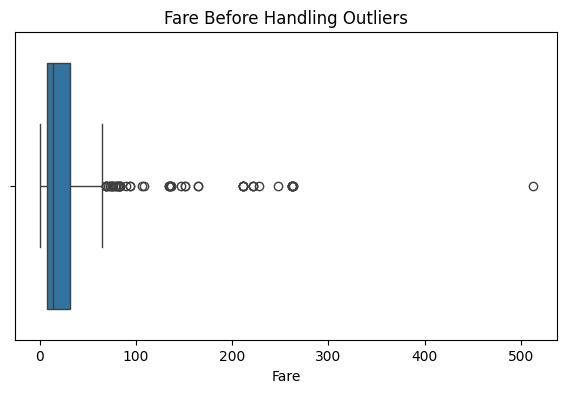

Number of Outliers: 55


In [16]:
plt.figure(figsize=(7,4))
sns.boxplot(x=df["Fare"])
plt.title("Fare Before Handling Outliers")
plt.show()

Q1 = df["Fare"].quantile(0.25)
Q3 = df["Fare"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = df[(df["Fare"] < lower) | (df["Fare"] > upper)]

print("Number of Outliers:", len(outliers))

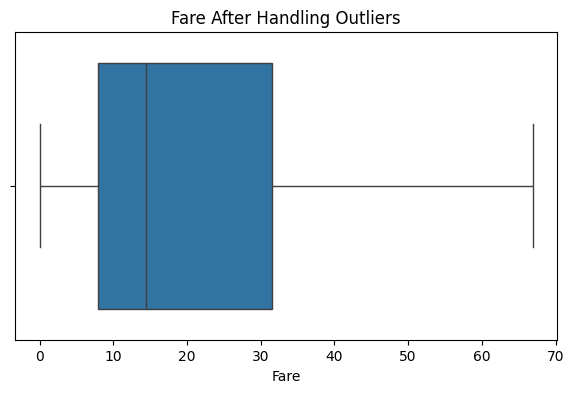

In [17]:
df["Fare"] = np.where(df["Fare"] > upper, upper, df["Fare"])
df["Fare"] = np.where(df["Fare"] < lower, lower, df["Fare"])

plt.figure(figsize=(7,4))
sns.boxplot(x=df["Fare"])
plt.title("Fare After Handling Outliers")
plt.show()

In [18]:
le = LabelEncoder()

df["Sex"] = le.fit_transform(df["Sex"])
df["Embarked"] = le.fit_transform(df["Embarked"])

df[["Sex","Embarked"]].head()

,Sex,Embarked
0,1,1
1,0,2
2,1,1
3,1,2
4,0,2


In [20]:
df_onehot = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/train.csv")

df_onehot["Age"] = df_onehot["Age"].fillna(df_onehot["Age"].median())
df_onehot["Embarked"] = df_onehot["Embarked"].fillna(df_onehot["Embarked"].mode()[0])

df_onehot.drop(columns=["Cabin"], inplace=True)

df_onehot = pd.get_dummies(
    df_onehot,
    columns=["Sex","Embarked"],
    drop_first=True
)

df_onehot.head()

,PassengerId,Survived,Pclass,Name,Age,SibSp,Parch,Ticket,Fare,Sex_male,Embarked_Q,Embarked_S
0,892,0,3,"Kelly, Mr. James",34.5,0,0,330911,7.8292,True,True,False
1,893,1,3,"Wilkes, Mrs. James (Ellen Needs)",47.0,1,0,363272,7.0000,False,False,True
2,894,0,2,"Myles, Mr. Thomas Francis",62.0,0,0,240276,9.6875,True,True,False
3,895,0,3,"Wirz, Mr. Albert",27.0,0,0,315154,8.6625,True,False,True
4,896,1,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",22.0,1,1,3101298,12.2875,False,False,True


In [35]:
minmax = MinMaxScaler()
df["Fare"] = df["Fare"].fillna(df["Fare"].median())
df["Age_MinMax"] = minmax.fit_transform(df[["Age"]])
df["Fare_MinMax"] = minmax.fit_transform(df[["Fare"]])

standard = StandardScaler()

df["Age_Standard"] = standard.fit_transform(df[["Age"]])
df["Fare_Standard"] = standard.fit_transform(df[["Fare"]])

df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked,Age_MinMax,Fare_MinMax,Age_Standard,Fare_Standard,FamilySize,IsAlone
0,892.0,0,3,"Kelly, Mr. James",1,34.5,0,0,330911,7.8292,1,0.452723,0.117017,0.386231,-0.794111,1,1
1,893.0,1,3,"Wilkes, Mrs. James (Ellen Needs)",0,47.0,1,0,363272,7.0000,2,0.617566,0.104624,1.371370,-0.833250,2,0
2,894.0,0,2,"Myles, Mr. Thomas Francis",1,62.0,0,0,240276,9.6875,1,0.815377,0.144792,2.553537,-0.706398,1,1
3,895.0,0,3,"Wirz, Mr. Albert",1,27.0,0,0,315154,8.6625,2,0.353818,0.129472,-0.204852,-0.754779,1,1
4,896.0,1,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",0,22.0,1,1,3101298,12.2875,2,0.287881,0.183652,-0.598908,-0.583675,3,0


In [36]:
corr = df.corr(numeric_only=True)

print(corr["Survived"].sort_values(ascending=False))

Survived         1.000000
Fare             0.204513
Fare_Standard    0.204513
Fare_MinMax      0.204513
FamilySize       0.161803
Parch            0.159120
SibSp            0.099943
Age              0.008035
Age_Standard     0.008035
Age_MinMax       0.008035
PassengerId     -0.023245
Embarked        -0.076281
IsAlone         -0.244187
Sex             -1.000000
Name: Survived, dtype: float64


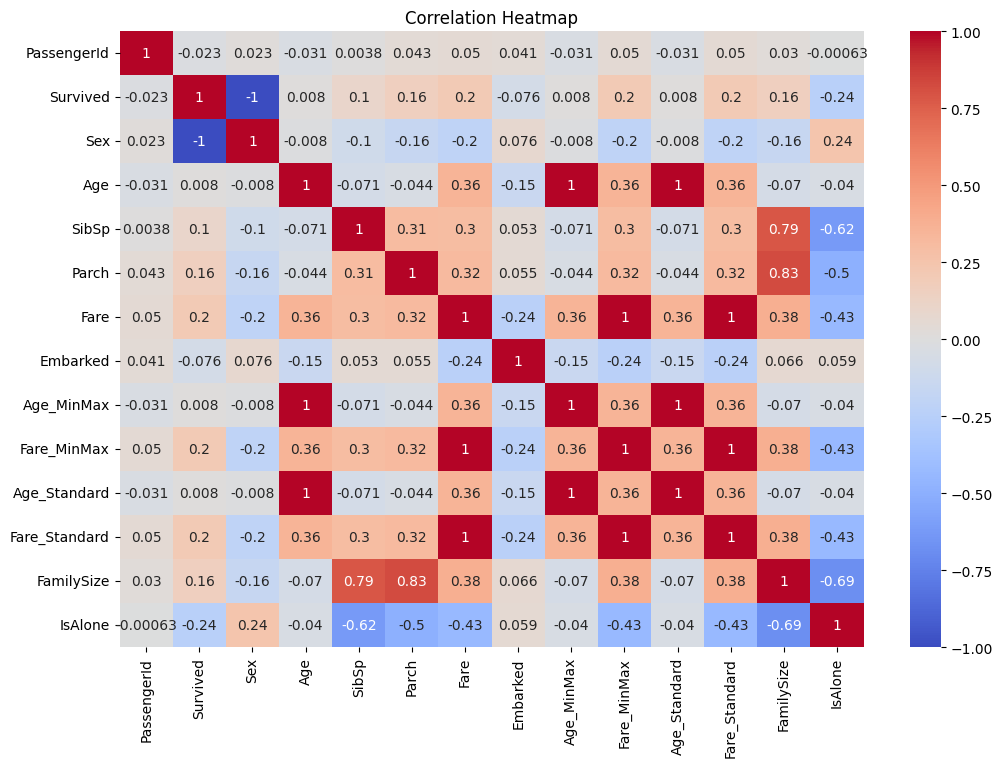

In [37]:
plt.figure(figsize=(12,8))

sns.heatmap(corr, annot=True, cmap="coolwarm")

plt.title("Correlation Heatmap")

plt.show()

In [38]:
df["FamilySize"] = df["SibSp"] + df["Parch"] + 1

df["IsAlone"] = (df["FamilySize"] == 1).astype(int)

df[["FamilySize","IsAlone"]].head()

,FamilySize,IsAlone
0,1,1
1,2,0
2,1,1
3,1,1
4,3,0


In [39]:
df["PassengerId"] = df["PassengerId"].astype(float)

df["Pclass"] = df["Pclass"].astype("category")

df.dtypes

,0
PassengerId,float64
Survived,int64
Pclass,category
Name,object
Sex,int64
Age,float64
SibSp,int64
Parch,int64
Ticket,object
Fare,float64


In [40]:
df["Name"] = df["Name"].str.strip()

df["Name"] = df["Name"].str.title()

df["Name"].head()

,Name
0,"Kelly, Mr. James"
1,"Wilkes, Mrs. James (Ellen Needs)"
2,"Myles, Mr. Thomas Francis"
3,"Wirz, Mr. Albert"
4,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)"


In [41]:
X = df.drop(columns=["Survived","Name","Ticket"])

X = X.select_dtypes(include=np.number)

y = df["Survived"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print(X_train.shape)

print(X_test.shape)

(334, 13)
(84, 13)


In [42]:
print("Before SMOTE")

print(y_train.value_counts())

smote = SMOTE(random_state=42)

X_train_balanced, y_train_balanced = smote.fit_resample(
    X_train,
    y_train
)

print("\nAfter SMOTE")

print(y_train_balanced.value_counts())

Before SMOTE
Survived
0    213
1    121
Name: count, dtype: int64

After SMOTE
Survived
0    213
1    213
Name: count, dtype: int64


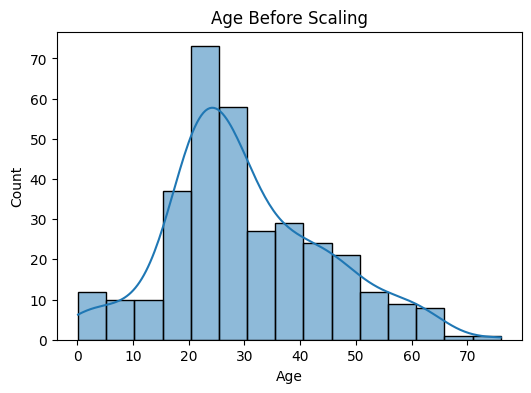

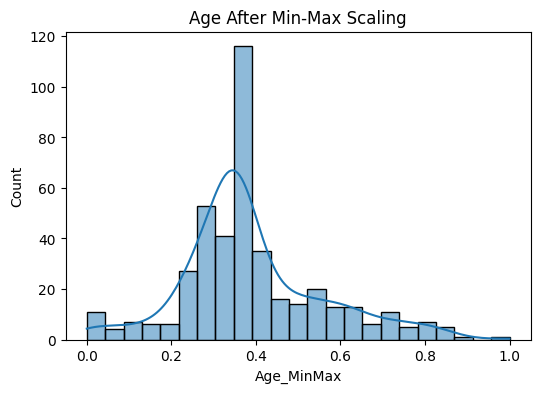

In [43]:
plt.figure(figsize=(6,4))

sns.histplot(original_df["Age"].dropna(), kde=True)

plt.title("Age Before Scaling")

plt.show()

plt.figure(figsize=(6,4))

sns.histplot(df["Age_MinMax"], kde=True)

plt.title("Age After Min-Max Scaling")

plt.show()

In [45]:
print("Original Shape :", original_df.shape)

print("Processed Shape :", df.shape)

print("\nOriginal Missing Values")

print(original_df.isnull().sum())

print("\nProcessed Missing Values")

print(df.isnull().sum())

Original Shape : (418, 12)
Processed Shape : (418, 17)

Original Missing Values
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age             86
SibSp            0
Parch            0
Ticket           0
Fare             1
Cabin          327
Embarked         0
dtype: int64

Processed Missing Values
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age              0
SibSp            0
Parch            0
Ticket           0
Fare             0
Embarked         0
Age_MinMax       0
Fare_MinMax      0
Age_Standard     0
Fare_Standard    0
FamilySize       0
IsAlone          0
dtype: int64


In [46]:
df.to_csv("Titanic_Preprocessed.csv", index=False)

print("Dataset saved successfully.")

Dataset saved successfully.
